In [2]:
# Q1
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

paragraph = """Data science is my favourite topic because it turns raw numbers into useful decisions.
Every day, companies collect huge amounts of data from apps, websites and sensors.
A data scientist cleans this data, explores it with charts, and builds models that predict what will happen next.
I enjoy using Python libraries like Pandas and NumPy, since they make difficult analysis feel simple.
Machine learning models aren't perfect, but they keep improving as they learn from more data.
In the future, I want to work on data problems that help people make better choices."""

# 1. Lowercase and remove punctuation
clean_text = re.sub(r"[^\w\s]", "", paragraph.lower())
print("1. Cleaned text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(clean_text)
sentences = sent_tokenize(paragraph)
print("\n2. Words:", words)
print("   Number of words:", len(words))
print("   Sentences:")
for s in sentences:
    print("   -", s)

# 3. split() vs word_tokenize() on the original paragraph
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)
print("\n3. split() gives", len(split_tokens), "tokens:", split_tokens[:20])
print("   word_tokenize() gives", len(nltk_tokens), "tokens:", nltk_tokens[:20])
print("   Only in split():", [t for t in split_tokens if t not in nltk_tokens])
print("   Only in word_tokenize():", sorted(set(t for t in nltk_tokens if t not in split_tokens)))

# 4. Remove stopwords
stop_words = set(stopwords.words("english"))
filtered = [w for w in words if w not in stop_words]
print("\n4. After removing stopwords:", filtered)

# 5. Word frequency distribution
freq = FreqDist(filtered)
print("\n5. Word frequencies:")
for word, count in freq.most_common():
    print("  ", word, ":", count)

1. Cleaned text:
 data science is my favourite topic because it turns raw numbers into useful decisions
every day companies collect huge amounts of data from apps websites and sensors
a data scientist cleans this data explores it with charts and builds models that predict what will happen next
i enjoy using python libraries like pandas and numpy since they make difficult analysis feel simple
machine learning models arent perfect but they keep improving as they learn from more data
in the future i want to work on data problems that help people make better choices

2. Words: ['data', 'science', 'is', 'my', 'favourite', 'topic', 'because', 'it', 'turns', 'raw', 'numbers', 'into', 'useful', 'decisions', 'every', 'day', 'companies', 'collect', 'huge', 'amounts', 'of', 'data', 'from', 'apps', 'websites', 'and', 'sensors', 'a', 'data', 'scientist', 'cleans', 'this', 'data', 'explores', 'it', 'with', 'charts', 'and', 'builds', 'models', 'that', 'predict', 'what', 'will', 'happen', 'next', 'i',

In [3]:
# Q2
import re
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1. Words with only alphabets
alpha_words = re.findall(r"\b[A-Za-z]+\b", paragraph.lower())
print("1. Alphabetic words:", alpha_words)

# 2. Remove stopwords
stop_words = set(stopwords.words("english"))
no_stop = [w for w in alpha_words if w not in stop_words]
print("\n2. After removing stopwords:", no_stop)

# 3. Stemming
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in no_stop]
print("\n3. Stemmed:", stemmed)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in no_stop]
print("\n4. Lemmatized:", lemmatized)

# 5. Compare
comparison = pd.DataFrame({"Word": no_stop, "Stemmed": stemmed, "Lemmatized": lemmatized})
comparison = comparison.drop_duplicates()
print("\n5. Words where stemming and lemmatization differ:")
print(comparison[comparison["Stemmed"] != comparison["Lemmatized"]].to_string(index=False))

1. Alphabetic words: ['data', 'science', 'is', 'my', 'favourite', 'topic', 'because', 'it', 'turns', 'raw', 'numbers', 'into', 'useful', 'decisions', 'every', 'day', 'companies', 'collect', 'huge', 'amounts', 'of', 'data', 'from', 'apps', 'websites', 'and', 'sensors', 'a', 'data', 'scientist', 'cleans', 'this', 'data', 'explores', 'it', 'with', 'charts', 'and', 'builds', 'models', 'that', 'predict', 'what', 'will', 'happen', 'next', 'i', 'enjoy', 'using', 'python', 'libraries', 'like', 'pandas', 'and', 'numpy', 'since', 'they', 'make', 'difficult', 'analysis', 'feel', 'simple', 'machine', 'learning', 'models', 'aren', 't', 'perfect', 'but', 'they', 'keep', 'improving', 'as', 'they', 'learn', 'from', 'more', 'data', 'in', 'the', 'future', 'i', 'want', 'to', 'work', 'on', 'data', 'problems', 'that', 'help', 'people', 'make', 'better', 'choices']

2. After removing stopwords: ['data', 'science', 'favourite', 'topic', 'turns', 'raw', 'numbers', 'useful', 'decisions', 'every', 'day', 'compa

In [4]:
# Q3
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The new phone has an amazing camera and the battery lasts all day.",
    "The laptop battery drains quickly but the screen quality is excellent.",
    "These wireless headphones give clear sound and a comfortable fit for long travel.",
]

# 1. Bag of Words
count_vec = CountVectorizer(stop_words="english")
bow = count_vec.fit_transform(texts)
bow_table = pd.DataFrame(bow.toarray(), columns=count_vec.get_feature_names_out(),
                         index=["Text 1", "Text 2", "Text 3"])
print("1. Bag of Words:")
print(bow_table.to_string())

# 2. TF-IDF
tfidf_vec = TfidfVectorizer(stop_words="english")
tfidf = tfidf_vec.fit_transform(texts)
tfidf_table = pd.DataFrame(tfidf.toarray().round(3), columns=tfidf_vec.get_feature_names_out(),
                           index=["Text 1", "Text 2", "Text 3"])
print("\n2. TF-IDF scores:")
print(tfidf_table.to_string())

# 3. Top 3 keywords per text
print("\n3. Top 3 keywords:")
for name, row in tfidf_table.iterrows():
    top = row.sort_values(ascending=False).head(3)
    print("  ", name, ":", [(word, score) for word, score in top.items()])

1. Bag of Words:
        amazing  battery  camera  clear  comfortable  day  drains  excellent  fit  headphones  laptop  lasts  long  new  phone  quality  quickly  screen  sound  travel  wireless
Text 1        1        1       1      0            0    1       0          0    0           0       0      1     0    1      1        0        0       0      0       0         0
Text 2        0        1       0      0            0    0       1          1    0           0       1      0     0    0      0        1        1       1      0       0         0
Text 3        0        0       0      1            1    0       0          0    1           1       0      0     1    0      0        0        0       0      1       1         1

2. TF-IDF scores:
        amazing  battery  camera  clear  comfortable   day  drains  excellent    fit  headphones  laptop  lasts   long   new  phone  quality  quickly  screen  sound  travel  wireless
Text 1     0.39    0.297    0.39  0.000        0.000  0.39    0.00   

In [5]:
# Q4
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_ai = """Artificial intelligence allows computers to learn from data and make decisions.
It uses machine learning models that are trained on large datasets.
AI is used in chatbots, self-driving cars and medical diagnosis.
These systems improve over time as they process more data.
The technology depends on powerful computers and good quality data."""

text_blockchain = """Blockchain is a digital ledger that stores records across many computers.
Each block holds transaction data and is linked to the previous block.
It is used in cryptocurrencies, supply chains and digital contracts.
The records are secure because they cannot be changed easily.
The technology depends on a network of computers instead of one central authority."""

# 1. Preprocess and tokenize
stop_words = set(stopwords.words("english"))

def preprocess(text):
    text = re.sub(r"[^\w\s]", "", text.lower())
    return [w for w in word_tokenize(text) if w not in stop_words]

tokens_ai = preprocess(text_ai)
tokens_blockchain = preprocess(text_blockchain)
print("1. AI tokens:", tokens_ai)
print("   Blockchain tokens:", tokens_blockchain)

# 2a. Jaccard similarity
set_ai, set_blockchain = set(tokens_ai), set(tokens_blockchain)
common = set_ai & set_blockchain
jaccard = len(common) / len(set_ai | set_blockchain)
print("\n2a. Common words:", sorted(common))
print("    Jaccard similarity:", round(jaccard, 3))

# 2b. Cosine similarity
tfidf = TfidfVectorizer().fit_transform([" ".join(tokens_ai), " ".join(tokens_blockchain)])
cosine = cosine_similarity(tfidf[0], tfidf[1])[0][0]
print("\n2b. Cosine similarity:", round(cosine, 3))

1. AI tokens: ['artificial', 'intelligence', 'allows', 'computers', 'learn', 'data', 'make', 'decisions', 'uses', 'machine', 'learning', 'models', 'trained', 'large', 'datasets', 'ai', 'used', 'chatbots', 'selfdriving', 'cars', 'medical', 'diagnosis', 'systems', 'improve', 'time', 'process', 'data', 'technology', 'depends', 'powerful', 'computers', 'good', 'quality', 'data']
   Blockchain tokens: ['blockchain', 'digital', 'ledger', 'stores', 'records', 'across', 'many', 'computers', 'block', 'holds', 'transaction', 'data', 'linked', 'previous', 'block', 'used', 'cryptocurrencies', 'supply', 'chains', 'digital', 'contracts', 'records', 'secure', 'changed', 'easily', 'technology', 'depends', 'network', 'computers', 'instead', 'one', 'central', 'authority']

2a. Common words: ['computers', 'data', 'depends', 'technology', 'used']
    Jaccard similarity: 0.091

2b. Cosine similarity: 0.142


                                                                                 Review  Polarity  Subjectivity Sentiment
The delivery was fast and the food was absolutely delicious. I loved the packaging too!     0.692         0.800  Positive
                              Terrible service. My order arrived cold and an hour late.    -0.633         0.867  Negative
                 The app is easy to use and the customer support team was very helpful.     0.317         0.567  Positive
                                        I ordered a pizza and it was delivered at 8 pm.     0.000         0.000   Neutral
    Great value for money, fresh ingredients and a wonderful taste. Highly recommended!     0.575         0.698  Positive
                  The worst experience ever, the food was stale and the staff was rude.    -0.600         0.700  Negative


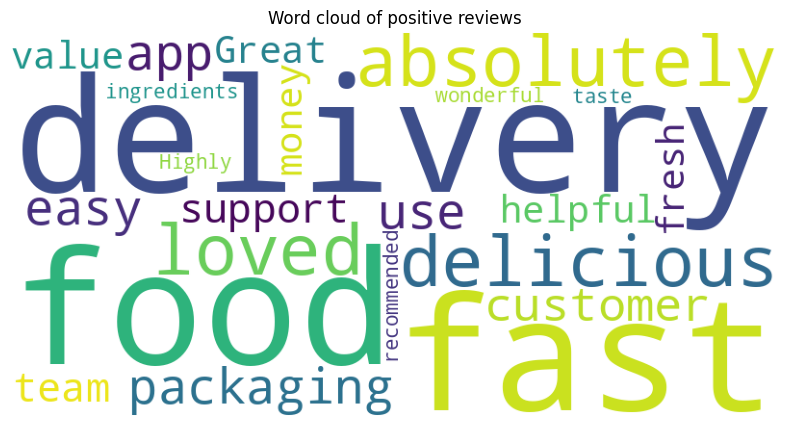

In [6]:
# Q5
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "The delivery was fast and the food was absolutely delicious. I loved the packaging too!",
    "Terrible service. My order arrived cold and an hour late.",
    "The app is easy to use and the customer support team was very helpful.",
    "I ordered a pizza and it was delivered at 8 pm.",
    "Great value for money, fresh ingredients and a wonderful taste. Highly recommended!",
    "The worst experience ever, the food was stale and the staff was rude.",
]

# 1 and 2. Polarity, subjectivity and classification
def classify(polarity):
    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    return "Neutral"

rows = []
for review in reviews:
    sentiment = TextBlob(review).sentiment
    rows.append({"Review": review,
                 "Polarity": round(sentiment.polarity, 3),
                 "Subjectivity": round(sentiment.subjectivity, 3),
                 "Sentiment": classify(sentiment.polarity)})

results = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
print(results.to_string(index=False))

# 3. Word cloud of positive reviews
positive_text = " ".join(results[results["Sentiment"] == "Positive"]["Review"])
cloud = WordCloud(width=800, height=400, background_color="white").generate(positive_text)
plt.figure(figsize=(10, 5))
plt.imshow(cloud)
plt.axis("off")
plt.title("Word cloud of positive reviews")
plt.show()

In [7]:
# Q6
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

tf.random.set_seed(42)
np.random.seed(42)

training_text = """Data science is the art of learning from data.
A data scientist collects data from many sources and cleans it carefully.
Clean data helps a model learn useful patterns.
A good model can predict future sales and customer behaviour.
Python is the most popular language for data science.
Pandas helps us organise data in tables.
NumPy helps us work with numbers quickly.
Machine learning helps computers learn from examples.
Deep learning uses neural networks with many layers.
Every company needs data to make better decisions.
Learning data science takes practice and patience."""

# 1. Tokenize
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
print("Words in training text:", len(training_text.split()))
print("Vocabulary size:", total_words)

# 2. Input sequences and model
sequences = []
for line in training_text.split("\n"):
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(tokens) + 1):
        sequences.append(tokens[:i])

max_len = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_len, padding="pre")
X, y = sequences[:, :-1], sequences[:, -1]
print("Training sequences:", len(X))

model = Sequential([
    Input(shape=(max_len - 1,)),
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# 3. Train and generate text
history = model.fit(X, y, epochs=200, verbose=0)
print("Final training accuracy:", round(history.history["accuracy"][-1], 3))

def generate(seed, n_words=8):
    text = seed
    for _ in range(n_words):
        tokens = tokenizer.texts_to_sequences([text])[0]
        tokens = pad_sequences([tokens], maxlen=max_len - 1, padding="pre")
        predicted = int(np.argmax(model.predict(tokens, verbose=0)))
        text += " " + tokenizer.index_word[predicted]
    return text

for seed in ["data", "machine", "python"]:
    print(seed, "->", generate(seed))

Words in training text: 92
Vocabulary size: 64
Training sequences: 81
Final training accuracy: 0.975
data -> data science is the art of learning from data
machine -> machine learning helps computers learn from examples examples patterns
python -> python is the most popular language for data science
